[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhconning/hunter_eco701/blob/main/notebooks/topic01_schelling_segregation.ipynb)

# Schelling Segregation as a Nash Equilibrium

This notebook builds Thomas Schelling's (1971) residential segregation model
from scratch and uses it to **reconstruct the specific 12-household example**
in Bowles & Halliday (2022), section 1.15 ("Application: Segregation as a
Nash Equilibrium Among People Who Prefer Integration") -- same population,
same starting arrangement, same three swaps, same final outcome. It then
goes beyond the book's single scripted walkthrough: a general simulator,
many random runs, and an interactive widget for exploring how sensitive the
outcome is to population size, group shares, and tolerance.

**The punchline this notebook makes rigorous:** every household's *stated
ideal* is one neighbor of each type. Nobody in this model wants segregation.
Yet a handful of individually sensible moves, starting from a fully mixed
neighborhood, can lock in complete segregation -- and once there, nobody
wants to move either. Two wildly different societies, same preferences
throughout; which one you get is a matter of history (the order people
happened to move), not preference.

**Corresponding slide**: `slides/01_definitions-and-key-tools/deck.md`,
"Postcard: Segregation as a Nash Equilibrium" -- that slide's figure is
generated at the end of Part 2 below.

Run with the `ecopy` kernel (`mamba run -n ecopy jupyter lab`).

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
from collections import Counter

NAVY = "#24325c"
AMBER = "#b8842a"
DISSATISFIED_RING = "#a04434"

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
})

FIGDIR = Path("../slides/01_definitions-and-key-tools/figs")
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")

## Part 1: The rule, in code

$n$ households sit on a circle, positions $0, \dots, n-1$ (circular: the
neighbor after the last position is the first). Each household has a type.
Household $i$'s neighbors are positions $i-1$ and $i+1 \pmod n$. Define its
**own-type neighbor count** $k_i \in \{0, 1, 2\}$: how many of its two
neighbors share its type.

A household is **satisfied** if $k_i \geq \tau$ for a tolerance threshold
$\tau$. Bowles & Halliday's rule is $\tau = 1$: satisfied unless *both*
neighbors are the other type. Note what this does *not* say -- a household
with one neighbor of each type ($k_i = 1$, its literal stated ideal) is
exactly as satisfied as one surrounded by its own type ($k_i = 2$). The only
thing intolerable is *zero*. We keep $\tau$ as a parameter throughout so we
can ask later how much this specific threshold matters.

A **move**: two dissatisfied households of *different* types may swap
places (swapping with your own type never helps -- you'd hand your problem
to someone identical to you). An arrangement is a **Nash equilibrium** when
every household is satisfied: nobody wants to move, so nobody does.

In [2]:
def neighbors(pos, n):
    "The two neighboring positions of `pos` on an n-circle."
    return [(pos - 1) % n, (pos + 1) % n]

def own_type_count(state, pos):
    "k_i: how many of pos's two neighbors share its type."
    n = len(state)
    left, right = neighbors(pos, n)
    return sum(1 for j in (left, right) if state[j] == state[pos])

def is_satisfied(state, pos, threshold=1):
    return own_type_count(state, pos) >= threshold

def dissatisfied_positions(state, threshold=1):
    return [i for i in range(len(state)) if not is_satisfied(state, i, threshold)]

def segregation_index(state):
    "Mean k_i across all households, in [0, 2]. Higher = more segregated."
    n = len(state)
    return np.mean([own_type_count(state, i) for i in range(n)])

# sanity checks against the definitions above
_toy = ["A", "A", "B", "B"]
assert own_type_count(_toy, 0) == 1   # neighbors are position 3 (B) and 1 (A)
assert own_type_count(_toy, 1) == 1
assert dissatisfied_positions(_toy, threshold=1) == []
print("core function checks pass")

core function checks pass


In [3]:
def plot_circle(ax, state, dissatisfied=None, title=None, label_positions=True):
    "Draw households as colored points around a circle, clock-style (position n at top)."
    n = len(state)
    dissatisfied = set(dissatisfied or [])
    colors = {state_val: (NAVY if idx == 0 else AMBER)
              for idx, state_val in enumerate(sorted(set(state)))}
    for i, s in enumerate(state):
        angle = np.pi / 2 - 2 * np.pi * (i + 1) / n
        x, y = np.cos(angle), np.sin(angle)
        if i in dissatisfied:
            ax.scatter([x], [y], s=340, facecolors="none",
                       edgecolors=DISSATISFIED_RING, linewidths=2.0, zorder=4)
        ax.scatter([x], [y], s=180, color=colors[s], zorder=5)
        if label_positions:
            ax.annotate(str(i + 1), (x, y), xytext=(x * 1.22, y * 1.22),
                        ha="center", va="center", fontsize=9, color="#555555")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=12.5, pad=6)
    return ax

def legend_handles(labels=("Group A", "Group B")):
    return [Line2D([0], [0], marker="o", color="none", markerfacecolor=NAVY,
                    markersize=10, label=labels[0]),
            Line2D([0], [0], marker="o", color="none", markerfacecolor=AMBER,
                    markersize=10, label=labels[1]),
            Line2D([0], [0], marker="o", color="none", markerfacecolor="none",
                    markeredgecolor=DISSATISFIED_RING, markeredgewidth=2,
                    markersize=12, label="dissatisfied")]

## Part 2: Reconstructing the book's own example

Twelve households, six of each type, arranged on a circle -- Bowles &
Halliday's "clock" (position 12 at the top, numbers increasing clockwise).
We start exactly where they do: strict alternation, the most thoroughly
mixed arrangement possible.

Book positions 1-12: ['B', 'G', 'B', 'G', 'B', 'G', 'B', 'G', 'B', 'G', 'B', 'G']
12 of 12 households dissatisfied: strict alternation satisfies no one


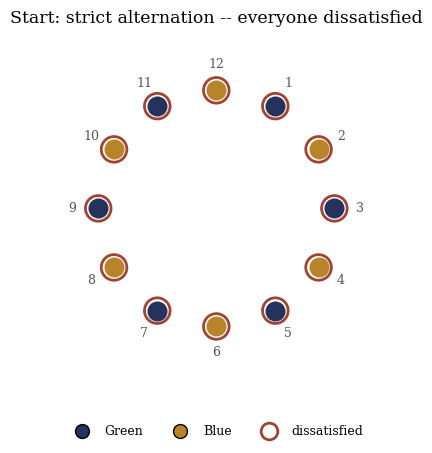

In [4]:
N = 12
# 1-indexed book positions 1..12 -> 0-indexed list entries 0..11.
# Alternating start: odd book-positions = 'B', even book-positions = 'G'.
state = ["B" if (i + 1) % 2 == 1 else "G" for i in range(N)]
print("Book positions 1-12:", state)

diss = dissatisfied_positions(state, threshold=1)
assert len(diss) == N, "every household should be dissatisfied at strict alternation"
print(f"{len(diss)} of {N} households dissatisfied: strict alternation satisfies no one")

fig, ax = plt.subplots(figsize=(4.6, 4.6))
plot_circle(ax, state, dissatisfied=diss,
            title="Start: strict alternation -- everyone dissatisfied")
ax.legend(handles=legend_handles(("Green", "Blue")), loc="lower center",
          bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False, fontsize=9)
plt.show()

**Step 1.** The book picks the Green at position 10: both neighbors (9 and
11) are Blue, so she is dissatisfied and signals. Her neighbor at position
11 (Blue) is also dissatisfied -- both of *his* neighbors (10 and 12) are
Green. They swap.

dissatisfied book positions: [1, 2, 3, 4, 5, 6, 7, 8]


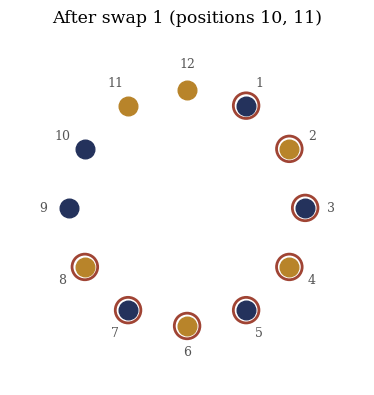

In [5]:
def book_position_to_index(p):
    return p - 1

def do_swap(state, book_pos_a, book_pos_b):
    i, j = book_position_to_index(book_pos_a), book_position_to_index(book_pos_b)
    state[i], state[j] = state[j], state[i]
    return state

assert state[book_position_to_index(10)] == "G" and state[book_position_to_index(11)] == "B"
state = do_swap(state, 10, 11)
diss = dissatisfied_positions(state, threshold=1)
print("dissatisfied book positions:", [i + 1 for i in diss])

fig, ax = plt.subplots(figsize=(4.6, 4.6))
plot_circle(ax, state, dissatisfied=diss, title="After swap 1 (positions 10, 11)")
plt.show()

**Step 2.** The Blue at position 1 is picked next: both neighbors (12 and
2) are Green, so he's dissatisfied. He swaps with his friend at position 8
(Green, also dissatisfied -- both of *its* neighbors, 7 and 9, are Blue).

dissatisfied book positions: [3, 4, 5, 6]


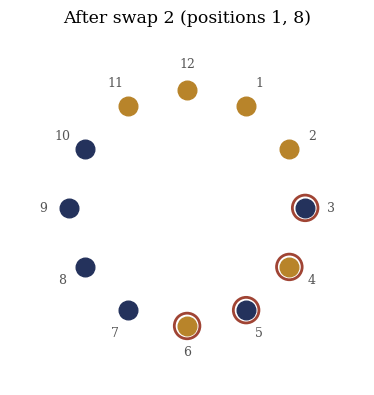

In [6]:
assert state[book_position_to_index(1)] == "B" and state[book_position_to_index(8)] == "G"
state = do_swap(state, 1, 8)
diss = dissatisfied_positions(state, threshold=1)
print("dissatisfied book positions:", [i + 1 for i in diss])

fig, ax = plt.subplots(figsize=(4.6, 4.6))
plot_circle(ax, state, dissatisfied=diss, title="After swap 2 (positions 1, 8)")
plt.show()

**Step 3.** Only positions 3, 4, 5, 6 remain dissatisfied (a small
alternating cluster left in the middle). Position 3 (Blue) and position 6
(Green) swap.

dissatisfied book positions: none
Confirmed: every household is satisfied. This is a Nash equilibrium.
Final arrangement (book positions 1-12): ['G', 'G', 'G', 'G', 'B', 'B', 'B', 'B', 'B', 'B', 'G', 'G']


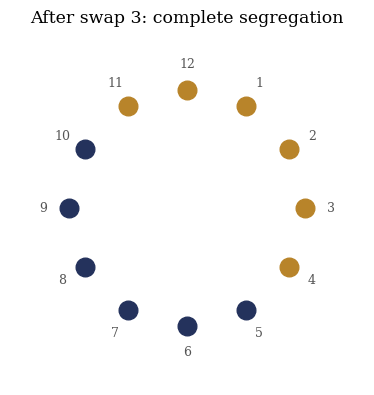

In [7]:
assert state[book_position_to_index(3)] == "B" and state[book_position_to_index(6)] == "G"
state = do_swap(state, 3, 6)
diss = dissatisfied_positions(state, threshold=1)
print("dissatisfied book positions:", [i + 1 for i in diss] or "none")

assert dissatisfied_positions(state, threshold=1) == [], "should be a full Nash equilibrium now"
print("Confirmed: every household is satisfied. This is a Nash equilibrium.")
print("Final arrangement (book positions 1-12):", state)

fig, ax = plt.subplots(figsize=(4.6, 4.6))
plot_circle(ax, state, dissatisfied=[], title="After swap 3: complete segregation")
plt.show()

saved ..\slides\01_definitions-and-key-tools\figs\schelling_before_after.png


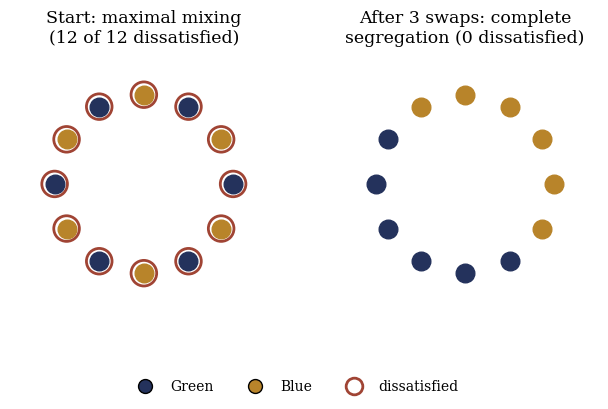

In [8]:
# The slide's figure: three swaps, from full mixing to full segregation.
segregated_state = list(state)

alternating_state = ["B" if (i + 1) % 2 == 1 else "G" for i in range(N)]

fig, axes = plt.subplots(1, 2, figsize=(7.6, 4.0))
plot_circle(axes[0], alternating_state,
            dissatisfied=dissatisfied_positions(alternating_state, threshold=1),
            title="Start: maximal mixing\n(12 of 12 dissatisfied)", label_positions=False)
plot_circle(axes[1], segregated_state, dissatisfied=[],
            title="After 3 swaps: complete\nsegregation (0 dissatisfied)", label_positions=False)
fig.legend(handles=legend_handles(("Green", "Blue")), loc="lower center",
           bbox_to_anchor=(0.5, -0.06), ncol=3, frameon=False, fontsize=10)
savefig(fig, "schelling_before_after.png")

## Part 3: The *other* equilibrium -- what everyone actually wants

The book also shows a second arrangement that is *just as stable*: blocks of
two. Every household gets exactly one neighbor of each type -- their
literal stated ideal, not merely tolerable.

Confirmed: blocks-of-two is also a Nash equilibrium, and it is everyone's literal ideal.


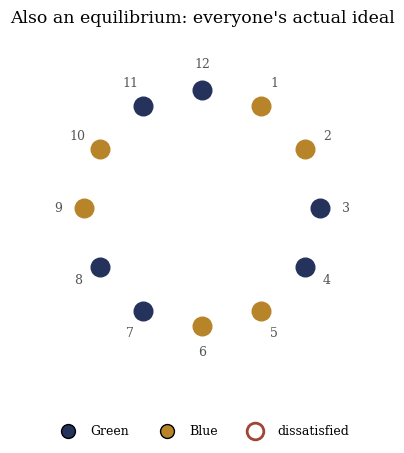


Same twelve people. Same preferences. Two equally stable societies:
  - segregation index (mean k_i) when fully segregated : 1.67
  - segregation index when fully integrated (ideal)     : 1.00
  - segregation index at the unstable starting point    : 0.00



In [9]:
ideal_state = []
for pair in range(N // 2):
    ideal_state += ["G", "G"] if pair % 2 == 0 else ["B", "B"]

diss_ideal = dissatisfied_positions(ideal_state, threshold=1)
assert diss_ideal == [], "the blocks-of-two arrangement should also be a Nash equilibrium"
assert all(own_type_count(ideal_state, i) == 1 for i in range(N)), \
    "every household should have exactly one neighbor of each type here"
print("Confirmed: blocks-of-two is also a Nash equilibrium, and it is everyone's literal ideal.")

fig, ax = plt.subplots(figsize=(4.6, 4.6))
plot_circle(ax, ideal_state, dissatisfied=[], title="Also an equilibrium: everyone's actual ideal")
ax.legend(handles=legend_handles(("Green", "Blue")), loc="lower center",
          bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False, fontsize=9)
plt.show()

print(
    "\nSame twelve people. Same preferences. Two equally stable societies:\n"
    f"  - segregation index (mean k_i) when fully segregated : {segregation_index(segregated_state):.2f}\n"
    f"  - segregation index when fully integrated (ideal)     : {segregation_index(ideal_state):.2f}\n"
    f"  - segregation index at the unstable starting point    : {segregation_index(alternating_state):.2f}\n"
)

## Part 4: Beyond the book's script -- random dynamics

The book walks through *one particular* sequence of moves. Real
dissatisfied households don't take turns in a scripted order. What happens
if, instead, we pick a random dissatisfied pair (one of each type) to swap
at each step, and repeat until nobody is left dissatisfied -- or until the
only households left dissatisfied are all the *same* type, with no
opposite-type partner to swap with (a possibility the book's script never
hits, but a real random process can)?

Random run from the checkerboard: equilibrium after 3 swaps, segregation index 1.33
(Notice this is not the clean full segregation of Part 2 - the book's 3-swap story is one specific path. Let's see if it's the typical one.)


saved ..\slides\01_definitions-and-key-tools\figs\schelling_index_over_time.png


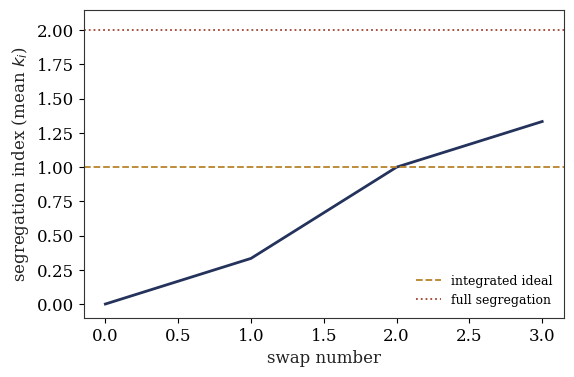

In [10]:
def simulate(initial_state, threshold=1, max_steps=2000, seed=None):
    "Repeatedly swap a random dissatisfied cross-type pair until equilibrium or stuck."
    rng = random.Random(seed)
    state = list(initial_state)
    history = [segregation_index(state)]
    for _ in range(max_steps):
        diss = dissatisfied_positions(state, threshold)
        if not diss:
            return state, history, "equilibrium"
        by_type = {}
        for i in diss:
            by_type.setdefault(state[i], []).append(i)
        if len(by_type) < 2:
            return state, history, "stuck (one type left, no partner)"
        types = list(by_type)
        i = rng.choice(by_type[types[0]])
        j = rng.choice(by_type[types[1]])
        state[i], state[j] = state[j], state[i]
        history.append(segregation_index(state))
    return state, history, "max steps reached"

final_state, history, status = simulate(alternating_state, threshold=1, seed=0)
print(f"Random run from the checkerboard: {status} after {len(history) - 1} swaps, "
      f"segregation index {history[-1]:.2f}")
print("(Notice this is not the clean full segregation of Part 2 - the book's 3-swap "
      "story is one specific path. Let's see if it's the typical one.)")

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.plot(history, color=NAVY, lw=2)
ax.axhline(1.0, ls="--", color=AMBER, lw=1.3, label="integrated ideal")
ax.axhline(2.0, ls=":", color=DISSATISFIED_RING, lw=1.3, label="full segregation")
ax.set_xlabel("swap number")
ax.set_ylabel("segregation index (mean $k_i$)")
ax.set_ylim(-0.1, 2.15)
ax.legend(fontsize=9, frameon=False)
savefig(fig, "schelling_index_over_time.png")

In [11]:
def count_clusters(state):
    "Number of maximal same-type runs around the circle (e.g. GGBB -> 2 clusters)."
    n = len(state)
    if len(set(state)) == 1:
        return 1
    return sum(1 for i in range(n) if state[i] != state[(i + 1) % n])

# Ground truth for the two textbook reference points - computed, not assumed.
# (mean k_i is a poor classifier here: full segregation on this circle size is
# 1.667, not close to the theoretical max of 2 - a circle split into exactly
# two same-type arcs always has four "boundary" households at k_i=1, not fewer.)
full_seg_clusters = count_clusters(segregated_state)
ideal_clusters = count_clusters(ideal_state)
print(f"full segregation reference: {full_seg_clusters} clusters, "
      f"segregation index {segregation_index(segregated_state):.3f}")
print(f"integrated ideal reference: {ideal_clusters} clusters, "
      f"segregation index {segregation_index(ideal_state):.3f}")

full segregation reference: 2 clusters, segregation index 1.667
integrated ideal reference: 6 clusters, segregation index 1.000


saved ..\slides\01_definitions-and-key-tools\figs\schelling_many_runs_hist.png
27% of random runs land on EXACTLY full segregation (2 clusters, matching the book's own outcome)
5% of random runs land on EXACTLY the integrated ideal (6 clusters)
68% land on some other patchwork - typically more clusters than full segregation, fewer than the ideal: several separate same-type neighborhoods rather than one giant one per group

Full segregation is common here, not rare - it just isn't the majority outcome. The typical (modal) result is a MILDER version of the same phenomenon: multiple smaller enclaves instead of one giant one per group. Full integration - everyone's literal stated ideal - is the one that's genuinely rare.


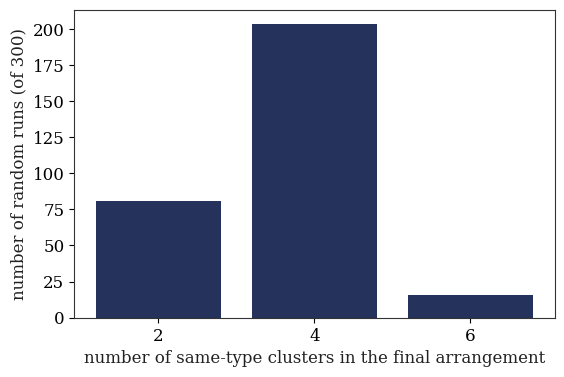

In [12]:
# One scripted run proves full segregation is *possible*. Many random runs
# show whether it is *typical* - and, as importantly, what the alternative is.
# Classify by cluster count (unambiguous), not by a segregation-index cutoff.
n_runs = 300
final_states = [simulate(alternating_state, threshold=1, seed=s)[0] for s in range(n_runs)]
final_clusters = [count_clusters(s) for s in final_states]

fig, ax = plt.subplots(figsize=(6.2, 4.0))
counts = Counter(final_clusters)
xs = sorted(counts)
ax.bar([str(x) for x in xs], [counts[x] for x in xs], color=NAVY)
ax.set_xlabel("number of same-type clusters in the final arrangement")
ax.set_ylabel(f"number of random runs (of {n_runs})")
savefig(fig, "schelling_many_runs_hist.png")

full_seg_share = sum(c == full_seg_clusters for c in final_clusters) / n_runs
ideal_share = sum(c == ideal_clusters for c in final_clusters) / n_runs
print(f"{full_seg_share:.0%} of random runs land on EXACTLY full segregation "
      f"({full_seg_clusters} clusters, matching the book's own outcome)")
print(f"{ideal_share:.0%} of random runs land on EXACTLY the integrated ideal "
      f"({ideal_clusters} clusters)")
print(f"{1 - full_seg_share - ideal_share:.0%} land on some other patchwork - "
      "typically more clusters than full segregation, fewer than the ideal: "
      "several separate same-type neighborhoods rather than one giant one per group")
print()
print("Full segregation is common here, not rare - it just isn't the majority outcome. "
      "The typical (modal) result is a MILDER version of the same phenomenon: multiple "
      "smaller enclaves instead of one giant one per group. Full integration - "
      "everyone's literal stated ideal - is the one that's genuinely rare.")

## Part 5: How sensitive is this to the parameters?

Three knobs: population size $n$, the share in Group A, and the tolerance
threshold $\tau$ (how many same-type neighbors a household needs to be
satisfied, out of its 2). $\tau=1$ replicates Bowles & Halliday's rule
exactly. $\tau=0$ means nobody is ever dissatisfied (no swaps ever happen).
$\tau=2$ means only "both neighbors my own type" counts as satisfied -- a
much less tolerant population.

In [13]:
def random_mixed_state(n, share_a, seed=None):
    rng = random.Random(seed)
    n_a = max(1, min(n - 1, round(n * share_a)))
    labels = ["G"] * n_a + ["B"] * (n - n_a)
    rng.shuffle(labels)
    return labels

def schelling_demo(n=16, share_a=0.5, threshold=1, seed=0):
    n = int(n)
    start = random_mixed_state(n, share_a, seed=seed)
    final, history, status = simulate(start, threshold=threshold, seed=seed)

    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
    plot_circle(axes[0], start, dissatisfied=dissatisfied_positions(start, threshold),
                title="Random start", label_positions=False)
    plot_circle(axes[1], final, dissatisfied=dissatisfied_positions(final, threshold),
                title=f"Outcome: {status}", label_positions=False)
    axes[2].plot(history, color=NAVY, lw=2)
    axes[2].axhline(1.0, ls="--", color=AMBER, lw=1.2)
    axes[2].axhline(2.0, ls=":", color=DISSATISFIED_RING, lw=1.2)
    axes[2].set_xlabel("swap number")
    axes[2].set_ylabel("segregation index")
    axes[2].set_ylim(-0.1, 2.15)
    fig.legend(handles=legend_handles(("Group A", "Group B")), loc="lower center",
               bbox_to_anchor=(0.22, -0.08), ncol=3, frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()
    print(f"n={n}, share A={share_a:.2f}, tolerance threshold={threshold}, seed={seed} "
          f"-> {status} after {len(history) - 1} swaps, "
          f"final segregation index {history[-1]:.2f}")

try:
    from ipywidgets import interact, IntSlider, FloatSlider
    interact(schelling_demo,
             n=IntSlider(value=16, min=6, max=40, step=2, description="n"),
             share_a=FloatSlider(value=0.5, min=0.1, max=0.9, step=0.05, description="share A"),
             threshold=IntSlider(value=1, min=0, max=2, step=1, description="tolerance"),
             seed=IntSlider(value=0, min=0, max=50, step=1, description="seed"))
except ImportError:
    schelling_demo()

interactive(children=(IntSlider(value=16, description='n', max=40, min=6, step=2), FloatSlider(value=0.5, desc…

## What this shows

- **Aggregation can betray individual preference.** Every household in this
  model prefers integration. The model never assumes anyone wants to
  segregate. Segregation emerges anyway, from uncoordinated, individually
  sensible moves - the whole is not simply the sum of its parts' wishes.
- **Multiple Nash equilibria, wildly different, both self-sustaining.**
  Fully segregated and fully (block-)integrated are both stable once
  reached (Part 3). Neither is a mistake, in the sense that nobody wants to
  deviate from either.
- **Full segregation is common, not rare - but it still isn't the typical
  outcome.** Part 4's many-run experiment finds the book's exact outcome
  (one contiguous block per group) in a real, sizeable share of random
  runs, not as some knife-edge special case. But it's not the modal
  outcome either: most random runs settle into a *milder* version of the
  same phenomenon - two or three separate same-type neighborhoods per
  group rather than one giant one. What's genuinely rare is landing on
  everyone's literal stated ideal (one neighbor of each type,
  everywhere). The lesson sharpens rather than overturns: history (who
  happened to signal, and to whom) picks *which* of many stable
  arrangements you get, spanning a whole range from mild to complete
  segregation - and the fully preferred outcome is the hardest of all
  to land on by chance.
- **Try the widget** (Part 5): even a fairly tolerant population
  (threshold 1 of 2) tips toward segregation almost every time; watch how
  much that changes as you push the tolerance to 0 or 2, or change the
  population's size and split.

## Promotion note

`schelling_before_after.png` is the figure used on the deck's postcard
slide. It lands in `slides/01_definitions-and-key-tools/figs/` (git-tracked,
regeneratable); promoting it to `media/` under the same name is a
deliberate `cp figs/schelling_before_after.png media/` - see HANDOFF.md's
"Code-generated figures" section. `schelling_index_over_time.png` and
`schelling_many_runs_hist.png` are supplementary - not currently referenced
by any slide, kept here as candidates if a future topic (9, most likely)
wants a fuller treatment.